<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.6_regressao_linear_salarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 2 — Regressão linear com dados reais: casas na Califórnia (treino × validação x teste)

Nesta atividade você vai treinar uma regressão linear com várias variáveis de entrada, em PyTorch, para prever o preço de casas na Califórnia. O dataset California Housing vem no scikit-learn e baixa sem login:

         from sklearn.datasets import fetch_california_housing
         dados = fetch_california_housing(as_frame=True)
         X, y = dados.data, dados.target # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares

Use como ponto de partida o notebook 2.6_regressao_linear_salarios.ipynb. O 2.6 tem uma variável de entrada; aqui são 8, então o modelo passa a ser nn.Linear(8, 1).

O notebook deve conter:
* Uma breve análise dos dados: o que cada variável significa,
describe() e um gráfico de dispersão de pelo menos duas variáveis contra o preço.
* Divisão em treino, validação e teste (por exemplo 70/15/15, com random_state fixo).
* Padronização das entradas e da saída com StandardScaler ajustado só no treino.
* Treinamento com nn.Linear(8, 1), nn.MSELoss e optim.SGD, com as curvas de custo de treino e de validação.
* RMSE no teste em dólares, comparado com um baseline que sempre prevê o preço médio do treino.
* Os 8 pesos aprendidos: quais variáveis mais aumentam e quais mais diminuem o preço previsto? Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?
* Uma conclusão curta: o modelo é bom o suficiente? O que você tentaria para melhorar?

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import fetch_california_housing

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Download



In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target     # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de US$
print('X:', X.shape, ' y:', y.shape)
df = dados.frame                    # X + coluna alvo 'MedHouseVal'
df.head()

X: (20640, 8)  y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### Leitura

In [3]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


 Cada linha é um quarteirão da Califórnia: 20.640 linhas, 8 variáveis de entrada e 1 alvo.


**Significado**

* MedInc:  renda mediana das famílias do quarteirão
* HouseAge: idade mediana das casas
* AveRooms: média de cômodos por domicílio
* AveBedrms: média de quartos por domicílio
* Population: número de moradores do quarteirão
* AveOccup: média de moradores por domicílio
* Latitude: latitude
* Longitude: longitude
* MedHouseVal (alvo): valor mediano das casas

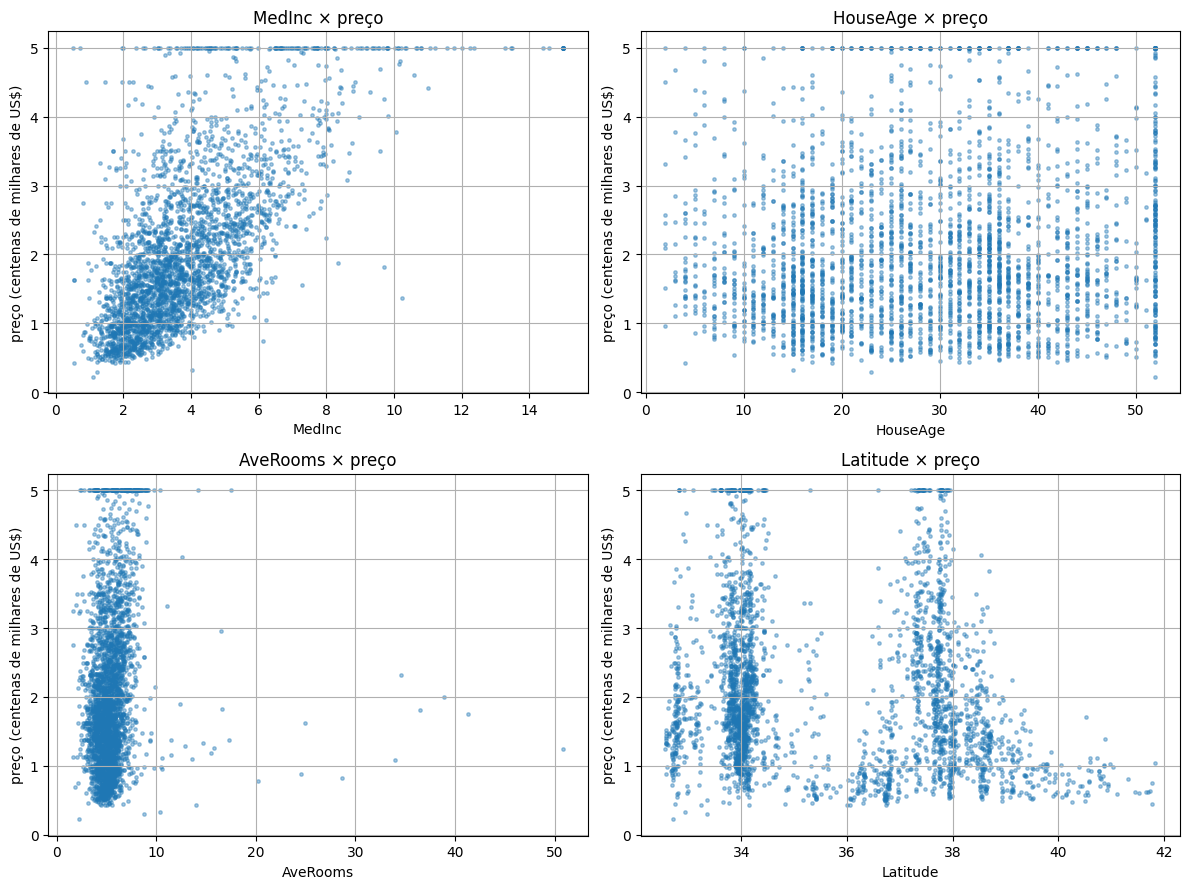

In [14]:
amostra = df.sample(3000, random_state=0)   # amostra só para o gráfico ficar legível
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axs.ravel(), ['MedInc', 'HouseAge', 'AveRooms', 'Latitude']):
    ax.scatter(amostra[col], amostra['MedHouseVal'], s=6, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel('preço (centenas de milhares de US$)')
    ax.set_title(f'{col} × preço')
    ax.grid(True)
plt.tight_layout()
plt.show()

Existe uma limitação de valor claro no valor 5 (ou US$ 500k), podemos ver uma relação direta entre a renda e o valor das casas e temos duas regiões onde os valores das casas sobem

### Treino × validação x teste



In [15]:
x_raw = X.to_numpy()                   # (20640, 8)
y_raw = y.to_numpy().reshape(-1, 1)    # (20640, 1)

x_train_raw, x_tmp_raw, y_train_raw, y_tmp_raw = train_test_split(
    x_raw, y_raw, test_size=0.30, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_tmp_raw, y_tmp_raw, test_size=0.50, random_state=42)

print('treino:', x_train_raw.shape, ' validação:', x_val_raw.shape, ' teste:', x_test_raw.shape)

treino: (14448, 8)  validação: (3096, 8)  teste: (3096, 8)


### Normalização



In [17]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()
x_val   = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val   = torch.from_numpy(y_scaler.transform(y_val_raw)).float()
x_test  = torch.from_numpy(x_scaler.transform(x_test_raw)).float()
y_test  = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_val:', x_val.shape, ' y_val:', y_val.shape)
print('x_test:', x_test.shape, ' y_test:', y_test.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
x_val: torch.Size([3096, 8])  y_val: torch.Size([3096, 1])
x_test: torch.Size([3096, 8])  y_test: torch.Size([3096, 1])


## Modelo


In [21]:
model = nn.Linear(8, 1)
print('weight:', model.weight, ' bias:', model.bias)

weight: Parameter containing:
tensor([[-0.0172,  0.2010, -0.2457,  0.1175, -0.1172,  0.2046, -0.1261,  0.0175]],
       requires_grad=True)  bias: Parameter containing:
tensor([0.1194], requires_grad=True)


## Treinamento

### Função de custo e otimizador

Os mesmos do 2.6.

In [22]:
lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)   # atualiza weight e bias

### Funções de treino e de validação


`train_epoch` faz um passo de gradiente descendente com todo o conjunto de treino e devolve o custo. `validate_epoch` só calcula o custo na validação, sem atualizar nada.

In [23]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)               # forward
    loss = criterion(y_pred, y_train)
    loss.backward()                       # backward
    optimizer.step()                      # atualiza weight e bias
    return loss.item()

def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():                 # sem grafo: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

A cada época: um passo de treino, a medida na validação. Observe que `train_loss` é medido no forward, antes do `step()` daquela época, e `val_loss` depois dele.

In [25]:
n_epochs = 300
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    val_loss = validate_epoch(model, criterion, x_val, y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    if (epoch + 1) % 50 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch[50/300], Train Loss: 0.3918, Val Loss: 0.4051
Epoch[100/300], Train Loss: 0.3907, Val Loss: 0.4039
Epoch[150/300], Train Loss: 0.3907, Val Loss: 0.4038
Epoch[200/300], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[250/300], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[300/300], Train Loss: 0.3907, Val Loss: 0.4037


## Avaliação

### Curvas de custo de treino e de validação

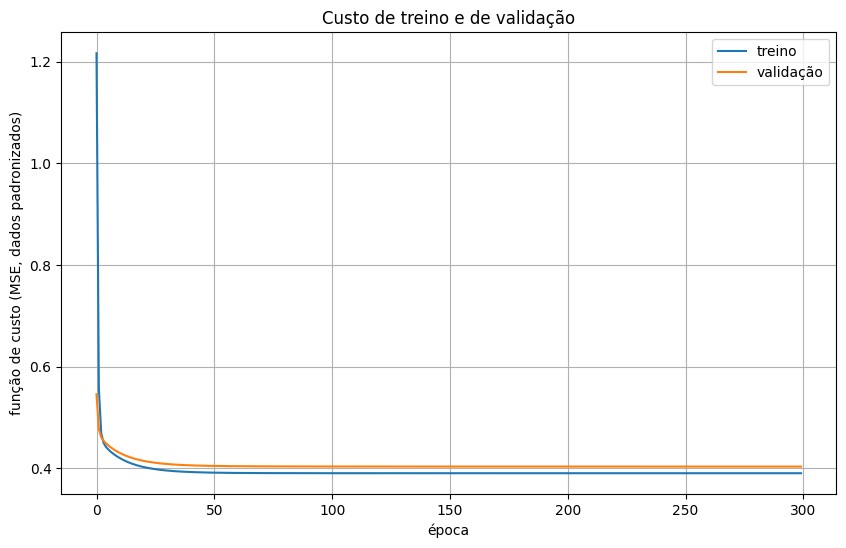

In [26]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

## RMSE no teste, em dólares, versus baseline

O conjunto de teste só entra agora. Levamos as previsões de volta para a escala original com `inverse_transform` e multiplicamos por 100.000 (o alvo está em centenas de milhares de US$).

In [27]:
model.eval()
with torch.no_grad():
    y_pred_test = model(x_test)

y_pred_test_raw = y_scaler.inverse_transform(y_pred_test.numpy())     # centenas de milhares de US$
y_base_raw = np.full_like(y_test_raw, y_train_raw.mean())             # sempre a média do treino

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_pred - y_true) ** 2))

rmse_model = rmse(y_test_raw, y_pred_test_raw) * 100_000
rmse_base  = rmse(y_test_raw, y_base_raw) * 100_000

print(f'RMSE no teste - modelo linear: US$ {rmse_model:,.0f}')
print(f'RMSE no teste - baseline:      US$ {rmse_base:,.0f}')
print(f'redução do erro: {100 * (1 - rmse_model / rmse_base):.1f}%')
print(f'preço médio no teste: US$ {y_test_raw.mean() * 100_000:,.0f}')

RMSE no teste - modelo linear: US$ 72,129
RMSE no teste - baseline:      US$ 114,992
redução do erro: 37.3%
preço médio no teste: US$ 206,596


## Os 8 pesos aprendidos

Como as entradas e a saída foram padronizadas, cada peso diz **quantos desvios padrão o preço previsto muda quando a variável sobe 1 desvio padrão**, mantidas as outras fixas. Na última coluna, convertemos para "US$ por unidade original" (só para dar intuição; essa coluna **não** serve para comparar variáveis entre si).

bias (w0): 0.0  (≈0, porque y foi padronizado)


,peso (padronizado),US$ por unidade original
MedInc,0.734,44583.614
AveBedrms,0.301,77868.892
HouseAge,0.106,968.227
Population,-0.001,-0.077
AveOccup,-0.036,-337.012
AveRooms,-0.259,-12211.486
Longitude,-0.750,-43366.032
Latitude,-0.772,-41850.934


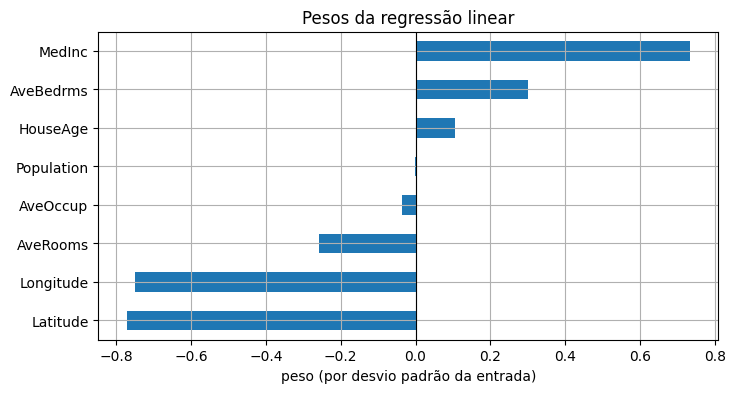

In [28]:
w = model.weight.detach().numpy().ravel()
efeito_usd = w * y_scaler.scale_[0] / x_scaler.scale_ * 100_000    # US$ por 1 unidade da variável original

pesos = pd.DataFrame({'peso (padronizado)': w,
                      'US$ por unidade original': efeito_usd},
                     index=X.columns).sort_values('peso (padronizado)', ascending=False)
print('bias (w0):', round(model.bias.item(), 4), ' (≈0, porque y foi padronizado)')
display(pesos.round(3))

plt.figure(figsize=(8, 4))
pesos['peso (padronizado)'].plot.barh()
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('peso (por desvio padrão da entrada)')
plt.title('Pesos da regressão linear')
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()

**Quais aumentam e quais diminuem o preço previsto**:

- **Aumentam:** `MedInc` (+0,73) é o maior peso positivo: bairros de renda mais alta, casas mais caras. `AveBedrms` (+0,30) e `HouseAge` (+0,11) têm peso positivo menor.
- **Diminuem:** `Latitude` (−0,77) e `Longitude` (−0,75) são os pesos de maior módulo, ou seja, a localização é o que mais pesa na previsão. `AveRooms` (−0,26) e `AveOccup` (−0,04) também ficam negativos. `Population` fica praticamente em zero.
- `AveRooms` e `AveBedrms` contrários parece estranho. Isso acontece porque as duas variáveis são fortemente correlacionadas entre si, e o peso de cada uma só vale "mantendo a outra fixa".

**Por que só dá para comparar os pesos porque padronizamos?** Sem padronização, o peso de uma variável depende da sua **unidade**: `Population` (milhares) teria um peso minúsculo e `AveRooms` (~5) um peso maior, só por causa da escala, não por importância. Com todas as entradas em desvios padrão (média 0, desvio 1), todas passam a ter a mesma "régua", e o módulo do peso mede a influência relativa de cada uma.

## Conclusão

**O modelo é bom o suficiente?** Mais ou menos. Ele aprendeu algo útil: o erro típico no teste (RMSE) ficou bem abaixo do baseline que sempre prevê o preço médio. Mas o erro ainda é grande em relação ao preço médio das casas, então eu não usaria esse modelo para estimar o preço de um imóvel de verdade.

As curvas de treino e de validação ficaram quase iguais. Isso mostra que o modelo não "decorou" o treino: ele se sai igualmente bem (ou mal) em dados novos. O problema é outro: o modelo é simples demais. Ele só sabe somar cada variável multiplicada por um peso, ou seja, só desenha uma reta (aqui, um plano em 8 dimensões). Mas a relação real entre, por exemplo, localização e preço não é uma reta, como vimos no gráfico de dispersão da latitude.

**O que eu tentaria para melhorar:**

1. **Usar um modelo mais flexível que uma reta.**
2. **Dar ao modelo informações mais úteis sobre localização.** Latitude e longitude separadas dizem pouco; combinar as duas (por exemplo, a distância até o litoral) ajudaria.
3. **Tratar os casos extremos e o teto do preço.** O `describe()` mostrou quarteirões com valores absurdos (`AveRooms` até 141, `AveOccup` até 1243) e preços cortados em US$ 500 mil. Remover ou tratar esses casos e treinar de novo pode ajudar. Treinar por mais épocas não ajudaria, porque o custo já estabilizou por volta da época 100.